## **MACHINE LEARNING MODEL**


### Model Objective

* **Primary Goal:** Classify job postings as **Specialized** or **Legacy** using only content-based features (`skill_counts`, `description_length`).
* **Environment Constraints:** Build from-scratch ML models (Logistic Regression & Decision Tree) using strictly `NumPy` and `Pandas` to bypass enterprise execution limits.


Step 1: Importing Libraries and Loading Data

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

INPUT_FILE = "cleaned_jobs.csv"
FEATURES = [
    "specialized_skill_count",
    "legacy_skill_count",
    "skill_count",
    "description_length",
]
TARGET = "tier_label"

df = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(df)} rows")
df.head()

Loaded 1710 rows


,search_keyword,search_keyword_encoded,tier_label,job_title,company,location,salary_min,salary_max,salary_avg,salary_disclosed,category,contract_type,posted_date,extracted_skills,skill_count,specialized_skill_count,legacy_skill_count,description_length,job_url
0,it-support,6,legacy,IT Support Engineer- Ahmedabad (Navrangpura),Miracle HR Solution,"Ahmedabad, Gujarat",3600000.0,4800000.0,4200000.0,True,IT Jobs,Not specified,2026-05-13 02:05:51+00:00,troubleshooting; hardware; technical support; ...,4,0,4,67,https://www.adzuna.in/details/5727156528?utm_m...
1,it-support,6,legacy,We Are Hiring IT Support Executive,Global Job Placement,"Morbi, Rajkot",4200000.0,4200000.0,4200000.0,True,IT Jobs,Not specified,2026-05-15 02:01:20+00:00,NaN,0,0,0,78,https://www.adzuna.in/details/5729555287?utm_m...
2,it-support,6,legacy,IT Support Executive,RECEX,"Mumbai, Maharashtra",2880000.0,3600000.0,3240000.0,True,IT Jobs,Not specified,2026-05-13 02:05:12+00:00,cloud; hardware; technical support; installati...,5,1,4,68,https://www.adzuna.in/details/5727149345?utm_m...
3,it-support,6,legacy,IT Support Executive (Networking & Hardware),Mantras2Success,"Ahmedabad, Gujarat",2400000.0,3600000.0,3000000.0,True,IT Jobs,Not specified,2026-05-13 02:17:45+00:00,troubleshooting; hardware; ms office; maintena...,6,0,6,71,https://www.adzuna.in/details/5727275157?utm_m...
4,it-support,6,legacy,IT Support Engineer,Real Placements,"Ahmedabad, Gujarat",1200000.0,3600000.0,2400000.0,True,IT Jobs,Not specified,2026-05-13 02:06:43+00:00,troubleshooting; networking; hardware,3,0,3,66,https://www.adzuna.in/details/5727166450?utm_m...


Step 2: Feature Matrix & Stratified Split

In [3]:
X = df[FEATURES].to_numpy(dtype=float)
y = (df[TARGET] == "specialized").astype(int).to_numpy()
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)


def stratified_split(X, y, test_size=0.2, seed=42):
  rng = np.random.default_rng(seed)
  train_idx, test_idx = [], []
  for cls in np.unique(y):
    cls_idx = np.where(y == cls)[0]
    rng.shuffle(cls_idx)
    n_test = int(len(cls_idx) * test_size)
    test_idx.extend(cls_idx[:n_test])
    train_idx.extend(cls_idx[n_test:])
  train_idx = np.array(train_idx)
  test_idx = np.array(test_idx)
  rng.shuffle(train_idx)
  rng.shuffle(test_idx)
  return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_tr, X_te, y_tr, y_te = stratified_split(X_scaled, y)
X_tr_raw, X_te_raw, _, _ = stratified_split(X, y)
print(f"Train size: {len(y_tr)}, Test size: {len(y_te)}")

Train size: 1369, Test size: 341


Step 3:Evaluation Metrics

In [4]:
def evaluate(name, y_true, y_pred):
  tp = np.sum((y_true == 1) & (y_pred == 1))
  fp = np.sum((y_true == 0) & (y_pred == 1))
  fn = np.sum((y_true == 1) & (y_pred == 0))
  acc = np.mean(y_true == y_pred)
  prec = tp / (tp + fp) if (tp + fp) else 0.0
  rec = tp / (tp + fn) if (tp + fn) else 0.0
  f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
  print(
      f"\n{name} -> Acc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f} | F1:"
      f" {f1:.3f}"
  )
  return acc

Step 4: Logistic Regression

In [5]:
class LogisticRegressionScratch:

  def __init__(self, lr=0.1, epochs=3000):
    self.lr, self.epochs = lr, epochs

  def fit(self, X, y):
    self.w, self.b = np.zeros(X.shape[1]), 0.0
    for _ in range(self.epochs):
      p = 1 / (1 + np.exp(-np.clip(X @ self.w + self.b, -500, 500)))
      err = p - y
      self.w -= self.lr * (X.T @ err) / len(y)
      self.b -= self.lr * err.mean()

  def predict(self, X):
    return (
        1 / (1 + np.exp(-np.clip(X @ self.w + self.b, -500, 500))) >= 0.5
    ).astype(int)


log_model = LogisticRegressionScratch()
log_model.fit(X_tr, y_tr)
log_preds = log_model.predict(X_te)
log_acc = evaluate("LOGISTIC REGRESSION", y_te, log_preds)

coef_df = pd.DataFrame({"feature": FEATURES, "coefficient": log_model.w}).sort_values("coefficient", ascending=False)
print("Logistic Regression Coefficients:")
print(coef_df.to_string(index=False))





LOGISTIC REGRESSION -> Acc: 0.865 | Prec: 0.826 | Rec: 0.945 | F1: 0.881
Logistic Regression Coefficients:
                feature  coefficient
specialized_skill_count     2.728337
     description_length     0.203842
            skill_count     0.006071
     legacy_skill_count    -3.129828


Step 5: Decision Tree

In [6]:
class DecisionTreeScratch:

  def __init__(self, max_depth=6, min_samples=20):
    self.max_depth, self.min_samples = max_depth, min_samples

  def _gini(self, y):
    return 1.0 - sum((np.mean(y == c)) ** 2 for c in [0, 1]) if len(y) else 0

  def _build(self, X, y, depth=0):
    if (
        depth >= self.max_depth
        or len(y) < self.min_samples
        or len(np.unique(y)) == 1
    ):
      return {"leaf": True, "pred": int(round(y.mean())) if len(y) else 0}

    best_gain, best_split = 0, None
    for f in range(X.shape[1]):
      for t in np.unique(X[:, f]):
        m = X[:, f] <= t
        if not m.any() or (~m).any() == 0:
          continue
        gain = self._gini(y) - (
            m.sum() * self._gini(y[m]) + (~m).sum() * self._gini(y[~m])
        ) / len(y)
        if gain > best_gain:
          best_gain, best_split = gain, (f, t, m)

    if not best_split:
      return {"leaf": True, "pred": int(round(y.mean()))}
    f, t, m = best_split
    return {
        "leaf": False,
        "f": f,
        "t": t,
        "l": self._build(X[m], y[m], depth + 1),
        "r": self._build(X[~m], y[~m], depth + 1),
    }

  def fit(self, X, y):
    self.tree = self._build(X, y)

  def _predict_one(self, x, node):
    if node["leaf"]:
      return node["pred"]
    return self._predict_one(x, node["l" if x[node["f"]] <= node["t"] else "r"])

  def predict(self, X):
    return np.array([self._predict_one(x, self.tree) for x in X])


tree_model = DecisionTreeScratch()
tree_model.fit(X_tr_raw, y_tr)
tree_preds = tree_model.predict(X_te_raw)
tree_acc = evaluate("DECISION TREE", y_te, tree_preds)
coef_df = pd.DataFrame({"feature": FEATURES, "coefficient": log_model.w}).sort_values("coefficient", ascending=False)
print("Logistic Regression Coefficients:")
print(coef_df.to_string(index=False))


DECISION TREE -> Acc: 0.868 | Prec: 0.874 | Rec: 0.878 | F1: 0.876
Logistic Regression Coefficients:
                feature  coefficient
specialized_skill_count     2.728337
     description_length     0.203842
            skill_count     0.006071
     legacy_skill_count    -3.129828


Step 6: Feature Importance & Plot

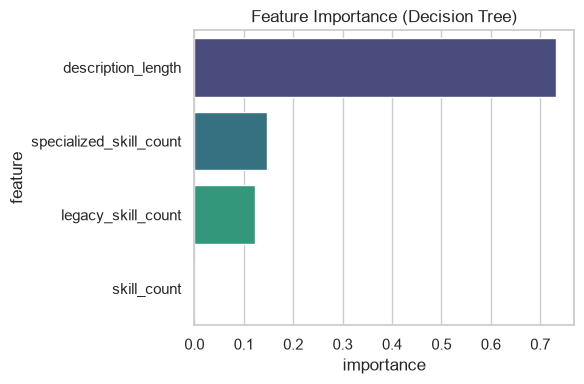

In [7]:
def get_tree_importance(tree, n_features):
  counts = np.zeros(n_features)

  def walk(node):
    if node["leaf"]:
      return
    counts[node["f"]] += 1
    walk(node["l"])
    walk(node["r"])

  walk(tree)
  total = counts.sum()
  return counts / total if total > 0 else counts


importance = get_tree_importance(tree_model.tree, len(FEATURES))
importance_df = pd.DataFrame(
    {"feature": FEATURES, "importance": importance}
).sort_values("importance", ascending=False)

plt.figure(figsize=(6, 4))
sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    hue="feature",
    palette="viridis",
    legend=False,
)
plt.title("Feature Importance (Decision Tree)")
plt.tight_layout()
plt.savefig("model_feature_importance.png", dpi=150)
plt.show()

Step 7: Confusion Matrices

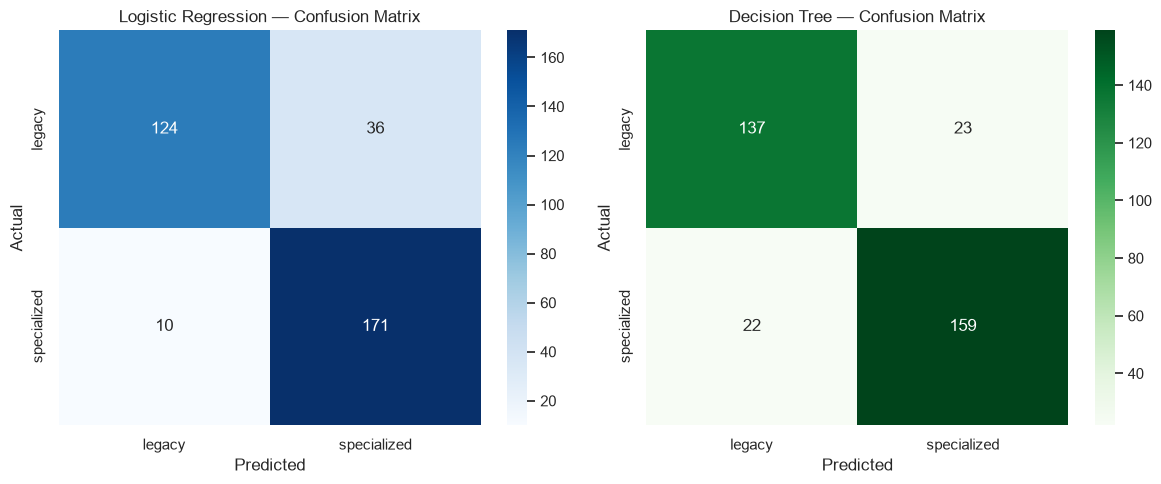

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


def get_cm(y_true, y_pred):
  return np.array([
      [
          np.sum((y_true == 0) & (y_pred == 0)),
          np.sum((y_true == 0) & (y_pred == 1)),
      ],
      [
          np.sum((y_true == 1) & (y_pred == 0)),
          np.sum((y_true == 1) & (y_pred == 1)),
      ],
  ])


sns.heatmap(
    get_cm(y_te, log_preds),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["legacy", "specialized"],
    yticklabels=["legacy", "specialized"],
    ax=axes[0],
)
axes[0].set_title("Logistic Regression — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    get_cm(y_te, tree_preds),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["legacy", "specialized"],
    yticklabels=["legacy", "specialized"],
    ax=axes[1],
)
axes[1].set_title("Decision Tree — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("model_confusion_matrices.png", dpi=150)
plt.show()

Step 8 :Export for Power BI

In [9]:
results_df = pd.DataFrame(X_te_raw, columns=FEATURES)
mapping = {0: "legacy", 1: "specialized"}
results_df["actual_tier"] = [mapping[v] for v in y_te]
results_df["pred_logreg"] = [mapping[v] for v in log_preds]
results_df["pred_tree"] = [mapping[v] for v in tree_preds]
results_df.to_csv("model_predictions.csv", index=False)
print("Saved predictions to model_predictions.csv")

Saved predictions to model_predictions.csv
